# **Part B – Practical (Python Programming)**

# ****Import all the Required Labraries****

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm
import os
os.makedirs("Charts", exist_ok=True)

# ****Import the Dataset****

In [2]:
DF = pd.read_csv(r"D:\OneDrive\Desktop\Practical Exam\loan_applications.csv")
DF

,Customer_ID,Age,Income,Loan_Amount,Credit_Score,Loan_Term,Default_Status
0,100001,41,46000,210000,686,36,No
1,100002,27,45000,208000,733,72,No
2,100003,46,37000,156000,579,36,Yes
3,100004,48,64000,234000,656,60,Yes
4,100005,21,58000,210000,729,72,No
...,...,...,...,...,...,...,...
4995,104996,50,113000,750000,702,12,No
4996,104997,34,50500,105000,675,36,No
4997,104998,47,54000,216000,596,60,No
4998,104999,39,89000,339000,611,60,No


# *****Check Null , Duplicates*****

In [3]:
Null = DF.isnull().sum()
Duplicate = DF.duplicated().sum()

print(f"Total No. of Null : \n{Null}")
print(f"\n\nTotal No. of Duplicates : {Duplicate}")

Total No. of Null : 
Customer_ID       0
Age               0
Income            0
Loan_Amount       0
Credit_Score      0
Loan_Term         0
Default_Status    0
dtype: int64


Total No. of Duplicates : 0


# **Step 1 : Central Tendency & Dispersion**

# *****1. Find Mean, Median and Mode of Income.*****

In [4]:
Mean = DF["Income"].mean()
Median = DF["Income"].median()
Mode = DF["Income"].mode()

print(f"Mean : {Mean}")
print(f"Median : {Median}")
print(f"Mode : {Mode[0]}")

Mean : 58482.8
Median : 51500.0
Mode : 47500


# *****2. Calculate Range, Variance and Standard Deviation of Loan_Amount.*****

In [5]:
Range = DF["Loan_Amount"].max() - DF["Loan_Amount"].min()
Variance = DF["Loan_Amount"].var()
Standard_Deviation = DF["Loan_Amount"].std()

print(f"Range : {round(Range , 4)}")
print(f"Variance : {round(Variance , 4)}")
print(f"Standard Deviation : {round(Standard_Deviation , 4)}")

Range : 1485000
Variance : 20608552064.1716
Standard Deviation : 143556.7904


# **Step 2 : Probability & Events.**

# *****1. Compute probability of loan default.*****

In [6]:
Total_Customers = len(DF["Default_Status"])
Default_Count = (DF["Default_Status"] == "Yes").sum()
Probability_Default = Default_Count / Total_Customers

print(f"Total Customers : {Total_Customers}")
print(f"Default Customers : {Default_Count}")
print(f"Probability of Default Customers : {round(Probability_Default * 100 , 2)} %")

Total Customers : 5000
Default Customers : 560
Probability of Default Customers : 11.2 %


# *****2. Create a contingency table between Default_Status and Credit_Score (categorized into ranges).*****

In [7]:
DF["Credit_Category"] = np.where(DF["Credit_Score"] <= 600 , "Low" , 
                        np.where(DF["Credit_Score"] <= 700 , "Medium" , "High"))

Contingency_Table = pd.crosstab(DF["Default_Status"] , DF["Credit_Category"])
Contingency_Table

Credit_Category,High,Low,Medium
Default_Status,,,
No,1548,498,2394
Yes,122,118,320


# *****3. Compute conditional probability: P(Default | mid Credit_Score < 600).*****

In [8]:
# Less_Credit = (DF["Credit_Score"] < 600).sum()
Total_Customer_Less_Credit = (DF["Credit_Score"] < 600).sum()
Default_Count_Less_Credit = ((DF["Credit_Score"] < 600) & (DF["Default_Status"] == "Yes")).sum()
Probability = Default_Count_Less_Credit / Total_Customer_Less_Credit

print(f"Default Customer who has Credit Score < 600 : {Default_Count_Less_Credit}")
print(f"Total Customer who has Credit Score < 600 : {Total_Customer_Less_Credit}")
print(f"Praobability : {round(Probability * 100 , 4)} %")

Default Customer who has Credit Score < 600 : 118
Total Customer who has Credit Score < 600 : 601
Praobability : 19.6339 %


# **Step 3: Distribution & Visualization.**

# *****1. Plot a Histogram of Credit_Score with a Gaussian curve.*****

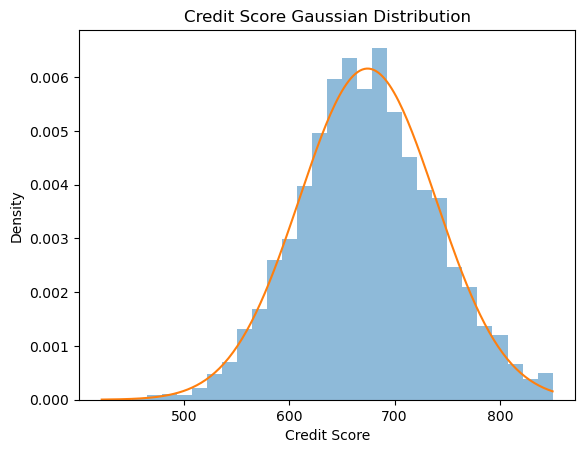

In [9]:
Mean = DF["Credit_Score"].mean()
Std = DF["Credit_Score"].std()

plt.hist(DF["Credit_Score"] , bins = 30 , density = True , alpha = 0.5)

X = np.linspace(DF["Credit_Score"].min() , DF["Credit_Score"].max() , 200)
Y = norm.pdf(X , Mean , Std)

plt.plot(X , Y)
plt.title("Credit Score Gaussian Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Density")
plt.show()

# *****2. Check Skewness and Kurtosis of Loan_Amount.*****

In [10]:
Skewness = DF["Loan_Amount"].skew()
Kurtosis = DF["Loan_Amount"].kurt()


if (Skewness < 0) :
    print("Distribution is Left Skewed.")
elif (Skewness > 0) :
    print("Distribution is Right Skewed.")
else :
    print("Distribution is Symmetric.")


if (Kurtosis < 0) :
    print("\nPlatykurtic Distribution.")
elif (Kurtosis > 0) :
    print("\nLeptokurtic Distribution.")
else :
    print("\nMesokurtic Distribution.")

Distribution is Right Skewed.

Leptokurtic Distribution.


# *****3. Draw a Q-Q Plot for Income.*****

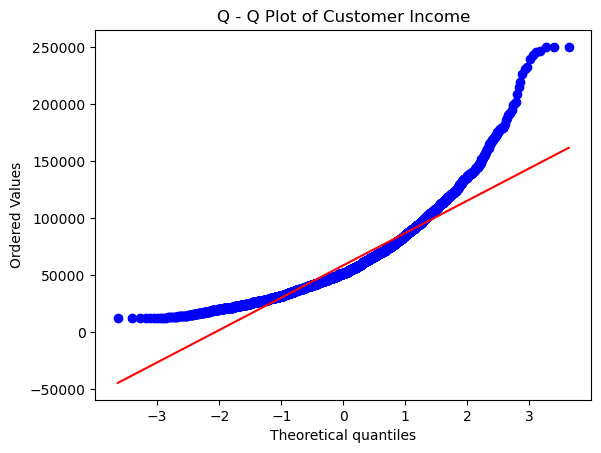

In [11]:
stats.probplot(DF["Income"] , dist = "norm" , plot = plt)

plt.title("Q - Q Plot of Customer Income")

plt.show()

# **Step 4 : Linear Algebra Application.**

# *****1. Perform dot product between two customer vectors.*****

In [12]:
Data = DF[["Income" , "Loan_Amount"]].head(5)
Vectors = Data.to_numpy()

A = Vectors[0]
B = Vectors[1]
Dot_Product = np.dot(A , B)

print(f"Customer 1 : {A}")
print(f"Customer 2 : {B}")
print(f"Dot Product : {Dot_Product}")

Customer 1 : [ 46000 210000]
Customer 2 : [ 45000 208000]
Dot Product : 45750000000


# *****2. Find Norm of a customer's financial vector.*****

In [13]:
A = Vectors[0]
Norm = np.linalg.norm(A)

print(f"Norm 2 : {Norm}")

Norm 2 : 214979.06874856446


# *****3. Calculate the angle between two customers' vectors.*****

In [14]:
A = Vectors[0]
B = Vectors[1]
Dot_Product = np.dot(A , B)

Norm_1 = np.linalg.norm(A)
Norm_2 = np.linalg.norm(B)

Cosine = Dot_Product / (Norm_1 * Norm_2)
Cosine = np.clip(Cosine , -1 , 1)

Radian = np.arccos(Cosine)

Degree = np.degrees(Radian)


print(f"Dot Product : {round(Dot_Product , 4)}")
print(f"Norm A : {round(Norm_1 , 4)}")
print(f"Norm B : {round(Norm_2 , 4)}")
print(f"Angle in Radian : {round(Radian , 4)}")
print(f"Angle in Degrees : {round(Degree , 4)}")

Dot Product : 45750000000
Norm A : 214979.0687
Norm B : 212812.1237
Angle in Radian : 0.0026
Angle in Degrees : 0.1478


# **All Charts Given Follow :**

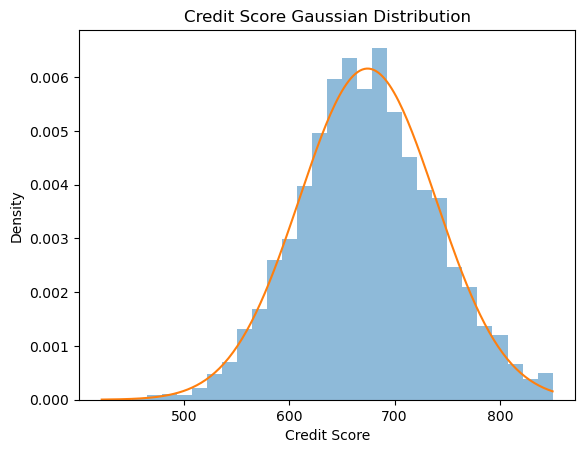

In [15]:
Mean = DF["Credit_Score"].mean()
Std = DF["Credit_Score"].std()

plt.hist(DF["Credit_Score"] , bins = 30 , density = True , alpha = 0.5)

X = np.linspace(DF["Credit_Score"].min() , DF["Credit_Score"].max() , 200)
Y = norm.pdf(X , Mean , Std)

plt.plot(X , Y)
plt.title("Credit Score Gaussian Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Density")
plt.savefig("Charts/Credit_Score.png")
plt.show()

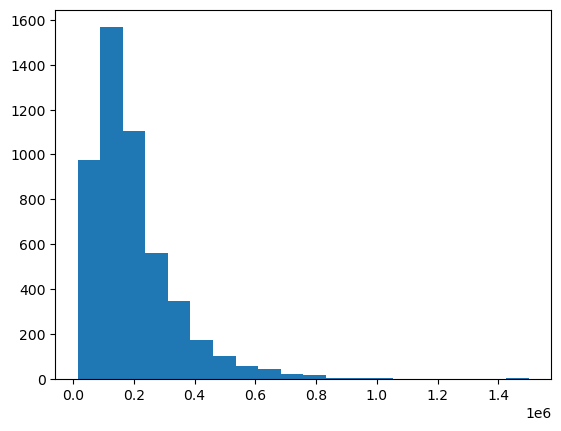

In [16]:
plt.hist(DF["Loan_Amount"] , bins = 20)
plt.savefig("Charts/Loan_Amount.png")
plt.show()

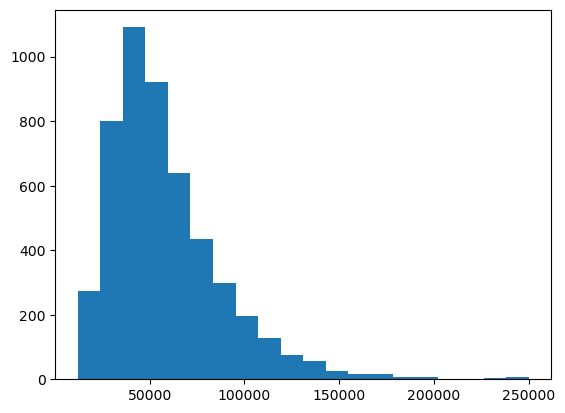

In [17]:
plt.hist(DF["Income"], bins=20)
plt.savefig("Charts/Income.png")
plt.show()

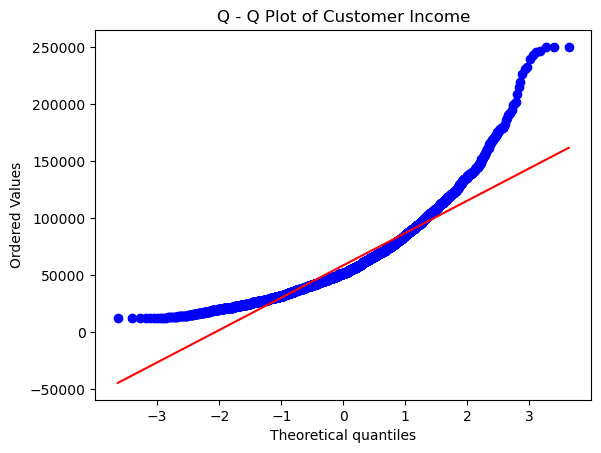

In [18]:
stats.probplot(DF["Income"] , dist = "norm" , plot = plt)

plt.title("Q - Q Plot of Customer Income")

plt.savefig("Charts/Income_QQ_Plot.png")
plt.show()